For 3:
Write one of the algorithms:
- Egg problem.
For +0.5: Draw a graph representing the dependency between:
- For egg problem – the number of floors k and the number of max and min operations.

## Egg problem

In [1]:
import matplotlib.pyplot as plt

def solve_egg_problem(n, k):
    if n <= 0 or k <= 0: 
        return 0, 0, 0, 0
        
    dp = [[0] * (k + 1) for _ in range(n + 1)]

    max_op_count = 0
    min_op_count = 0

    for i in range(n + 1):
        dp[i][0] = 0
        dp[i][1] = 1
        
    for i in range(k + 1):
        dp[1][i] = i

    for e in range(2, n + 1):
        for f in range(2, k + 1):
            dp[e][f] = float("inf")
            
            for i in range(1, f + 1):
                worst_case = 1 + max(dp[e - 1][i - 1], dp[e][f - i])
                max_op_count += 1

                dp[e][f] = min(dp[e][f], worst_case)
                min_op_count += 1
    total_max_min_ops = max_op_count + min_op_count
    return dp[n][k], max_op_count, min_op_count, total_max_min_ops

def plot_egg_drop_operations(n_eggs, max_floors):
    k_values = list(range(1, max_floors + 1))
    max_counts = []
    min_counts = []
    total_ops = []

    for k in k_values:
        _, c_max, c_min, c_total = solve_egg_problem(n_eggs, k)
        max_counts.append(c_max)
        min_counts.append(c_min)
        total_ops.append(c_total)

    plt.figure(figsize=(8, 5))
    plt.plot(k_values, total_ops, label="Total (max + min) operations", color="crimson", linewidth=2)
    plt.plot(k_values, max_counts, label="Number of max() operations", color="royalblue", linestyle="--", linewidth=2)
    plt.plot(k_values, min_counts, label="Number of min() operations", color="forestgreen", linestyle=":", linewidth=2)

    plt.title(f"Egg Problem (n = {n_eggs}): Floors (k) vs Number of Max & Min Operations")
    plt.xlabel("Number of floors (k)")
    plt.ylabel("Number of operations executed")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()



result:  4


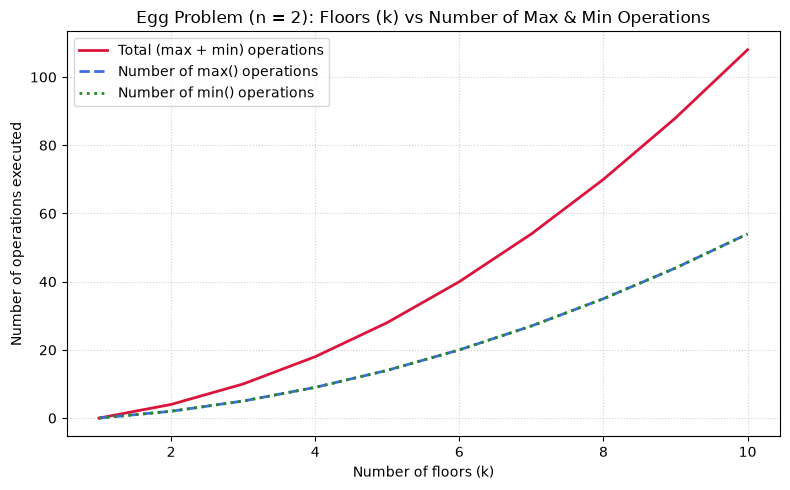

In [2]:
eggs = 2 
floors = 10
print("result: ", solve_egg_problem(eggs, floors)[0])
plot_egg_drop_operations(eggs, floors)


For 4:
For change making problem write two algorithms greedy (from the lecture) and dynamic programming algorithm. As the result there should be information only about how many coins we need.

For +0.5: Draw a graph for a greedy algorithm representing the dependency between the value and the number of all arithmetic operations.

For +0.5: Draw a graph for a dynamic programming algorithm representing the dependency between the value and the number of all arithmetic operations.

For +1: For both algorithms print the information about what coins exactly we need.


In [3]:
import matplotlib.pyplot as plt

def solve_change_making_greedy(n, coins): 
    if n < 0 or not isinstance(coins, list) or any(c <= 0 for c in coins):
        print("Invalid input values")
        return None, 0, 0, 0, 0
    
    copied_coins = sorted(coins, reverse=True)
    coins_count = 0
    chosen_coins = {}
    
    sub_ops = 0  
    add_ops = 0
    for num in copied_coins: 
        while n >= num:
            n = n - num
            sub_ops += 1
            
            coins_count += 1
            add_ops += 1
            
            chosen_coins[num] = chosen_coins.get(num, 0) + 1
            
    total_ops = sub_ops + add_ops
    if n > 0:
        print("Cannot exchange the money")
        return None, 0, sub_ops, add_ops, total_ops
    else:
        return chosen_coins, coins_count, sub_ops, add_ops, total_ops

def plot_greedy_change_dependency(coins, max_amount=50): 
    amounts = list(range(1, max_amount + 1))
    total_ops_list = []
    sub_ops_list = []
    add_ops_list = []
    coins_used_list = []
    for x in amounts:
        chosen, count, s_ops, a_ops, tot_ops = solve_change_making_greedy(x, coins)
        total_ops_list.append(tot_ops)
        sub_ops_list.append(s_ops)
        add_ops_list.append(a_ops)
        coins_used_list.append(count if count is not None else 0)
    plt.figure(figsize=(9, 5))
    plt.plot(amounts, total_ops_list, label="Total Arithmetic Operations (- and +)", color="crimson", linewidth=2)
    plt.plot(amounts, sub_ops_list, label="Subtractions (-)", color="royalblue", linestyle="--", linewidth=1.5)
    plt.plot(amounts, add_ops_list, label="Additions (+)", color="forestgreen", linestyle=":", linewidth=1.5)
    plt.plot(amounts, coins_used_list, label="Number of Coins Used", color="purple", linestyle="-.", linewidth=1.5)
    plt.title(f"Greedy Change-Making (Coins: {coins}): Value vs Arithmetic Operations")
    plt.xlabel("Value to Exchange (n)")
    plt.ylabel("Number of operations")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()


            

Chosen: {5: 1, 1: 1}; count: 2 coins


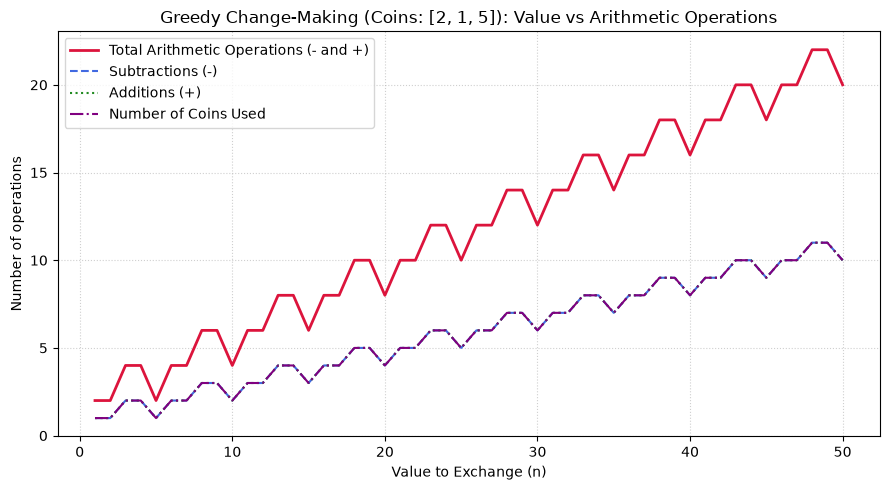

In [4]:
coins = [2, 1, 5]
max_amount = 50

result = solve_change_making_greedy(6, coins)

print(f"Chosen: {result[0]}; count: {result[1]} coins")

plot_greedy_change_dependency(coins, max_amount)

In [5]:
import matplotlib.pyplot as plt

def solve_change_making_dp(n, coins):
    if n < 0 or not isinstance(coins, list) or any(c <= 0 for c in coins):
        print("Invalid input values")
        return None

    m = len(coins)
    INF = float("inf")

    dp = [[INF] * (n + 1) for _ in range(m + 1)]
    operations = 0

    for i in range(m + 1):
        dp[i][0] = 0

    for i in range(1, m + 1):
        coin = coins[i - 1]
        for j in range(1, n + 1):
            if j < coin:
                dp[i][j] = dp[i - 1][j]
            else:
                # Min between:
                # 1. dp[i - 1][j]: Don't use coin i
                # 2. 1 + dp[i][j - coin]: Use coin i at least once
                
                operations += 1 # coin ammount - coin
                previous = dp[i][j - coin]
                
                operations += 1 # 1 + previous 
                using_coin = 1 + previous
                
                dp[i][j] = min(dp[i - 1][j], using_coin)

    result = dp[m][n]
    if result == INF:
        print("Cannot exchange the money")
        return dp, 0, 0
    
    return dp, result, operations

def traverse_chosen_coins(dp, coins):
    chosen = []
    i, remaining = len(coins), len(dp[0]) - 1 
    
    while i > 0 and remaining > 0: 
        if dp[i][remaining] == dp[i - 1][remaining]:
            i -= 1
        else:
            coin = coins[i - 1]
            chosen.append(coin)
            remaining -= coin
            
    chosen.reverse()
    return chosen

def plot_chart_change_making_dp(n, coins):
    ammounts = range(1, n + 1)
    dp_counts = [solve_change_making_dp(i, coins)[2] for i in ammounts]
    plt.plot(ammounts, dp_counts, label="Dynamic programming")
    plt.xlabel("Target amount")
    plt.ylabel("Arithmetic operations")
    plt.title("Operation count vs. target amount")
    plt.grid(True)
    plt.legend()
    plt.show()


In [6]:
coins = [1, 2, 5]
dp, result, operations = solve_change_making_dp(14, coins)
returned_coins = traverse_chosen_coins(dp, coins)
print(f"returned_coins: {returned_coins}")

returned_coins: [2, 2, 5, 5]


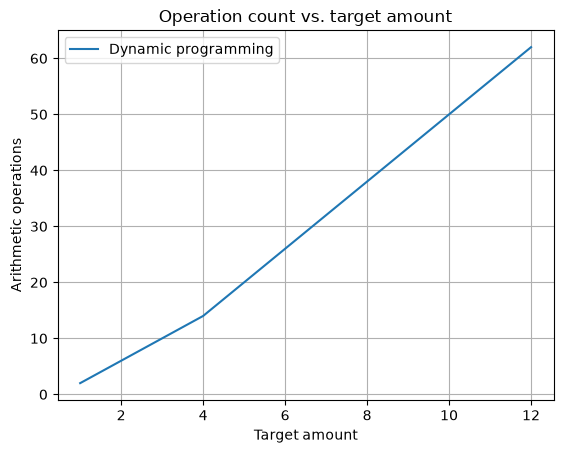

In [7]:
plot_chart_change_making_dp(12, coins)

For 5:
Implement the algorithm for backpacking problem (using branch and bound solution).

In [8]:
class Item:
    def __init__(self, name, weight, value):
        self.name = name
        self.weight = weight
        self.value = value

def solve_backpacking(items, capacity):
    def calculate_bound(items, start_index, curr_weight, curr_value, capacity):
        if curr_weight > capacity:
            return -1
        bound = curr_value
        remaining = capacity - curr_weight
        
        for item in items[start_index:]:
            if item.weight <= remaining:
                bound += item.value
                remaining -= item.weight
            else:
                bound += item.value * (remaining / item.weight)
                break
        return bound
    
    sorted_items = sorted(items, key=lambda item: item.value / item.weight, reverse=True)
    best = {
        "value": 0,
        "weight": 0,
        "items": []
    }
    
    def recursive(curr_i, curr_weight, curr_value, chosen):
        if curr_weight > capacity:
            return
        
        if curr_value > best["value"]:
            best["value"] = curr_value
            best["weight"] = curr_weight
            best["items"] = chosen.copy()
        
        if curr_i >= len(sorted_items):
            return
        
        bound = calculate_bound(sorted_items, curr_i, curr_weight, curr_value, capacity)
        if bound <= best["value"]:
            return
        
        item = sorted_items[curr_i]
        
        recursive(curr_i + 1, curr_weight + item.weight, curr_value + item.value, chosen + [item])
        recursive(curr_i + 1, curr_weight, curr_value, chosen)
    
    recursive(0, 0, 0, [])
    return best
        

In [9]:
items = [
    Item("Apples", 2, 6),
    Item("Oranges", 2.5, 8),
    Item("Kiwis", 1, 7)
]
result = solve_backpacking(items, 4)


In [10]:

print("Max values:", result["value"])
print("Sum weights:", result["weight"], "kg")
print("Selected items:", [item.name for item in result["items"]])

Max values: 15
Sum weights: 3.5 kg
Selected items: ['Kiwis', 'Oranges']
